# Prédiction du churn client dans les télécoms

**Auteur :** David Diop, Master 2 Économétrie appliquée, IAE Nantes

**Question métier :** quels clients risquent de résilier leur abonnement le mois prochain,
et lesquels faut-il contacter en priorité avec une offre de fidélisation ?

**Données :** *Telco Customer Churn* (IBM), 7 043 clients d'un opérateur télécom fictif :
services souscrits, type de contrat, facturation, ancienneté, et résiliation (oui/non).

**Démarche :**
1. Qualité des données (avec des requêtes SQL)
2. Exploration
3. Préparation des données
4. Comparaison de 4 modèles par validation croisée
5. Évaluation sur un échantillon test jamais vu
6. Le meilleur modèle est-il *significativement* meilleur ? (bootstrap)
7. Choix d'un seuil de décision selon un critère métier (gain d'une campagne de fidélisation)
8. Interprétation : odds ratios (régression logistique) et valeurs SHAP (XGBoost)

In [5]:
# Bibliothèques
import warnings
warnings.filterwarnings("ignore")   # masque les avertissements techniques sans importance ici

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score,
                             recall_score, f1_score, confusion_matrix)
from xgboost import XGBClassifier

SEED = 42                      # graine aléatoire : rend les résultats reproductibles
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

## 1. Qualité des données

In [27]:
df = pd.read_csv("../data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Avant toute analyse, je vérifie la qualité des données : doublons, valeurs manquantes, types de colonnes.

In [28]:
print("Doublons sur l'identifiant client :", df["customerID"].duplicated().sum())
print("Valeurs manquantes (NaN) :", df.isna().sum())
print()
print(df.dtypes.value_counts())


Doublons sur l'identifiant client : 0
Valeurs manquantes (NaN) : customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

object     18
int64       2
float64     1
dtype: int64


Aucun NaN apparent… 

In [29]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


 `TotalCharges` (montant total facturé) est lue comme du **texte** alors que
c'est un montant.

In [30]:
num_total = pd.to_numeric(df["TotalCharges"], errors="coerce")   # texte -> nombre, NaN si impossible
pb = df[num_total.isna()]
print(len(pb), "lignes où TotalCharges n'est pas un nombre")
pb[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

11 lignes où TotalCharges n'est pas un nombre


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Ces 11 clients ont une ancienneté (`tenure`) de **0 mois** : ce sont des clients tout juste arrivés,
qui n'ont pas encore été facturés. La valeur logique est donc **0**, pas une valeur manquante à imputer.

In [31]:
df["TotalCharges"] = num_total.fillna(0)

# Variable cible en 0/1
df["Churn"] = df["Churn"].apply(lambda valeur: 1 if valeur == "Yes" else 0)

# "No internet service" et "No phone service" répètent l'information déjà présente
# dans InternetService et PhoneService : je les remplace par "No" pour éviter
# des variables parfaitement redondantes (colinéarité dans la régression logistique).
df = df.replace({"No internet service": "No", "No phone service": "No"})

## 2. Exploration

In [34]:
taux = df["Churn"].mean()
print(f"Taux de churn global : {taux:.1%}")

Taux de churn global : 26.5%


Environ **un client sur quatre** est parti : les classes sont **déséquilibrées**.
Conséquence : l'*accuracy* (taux de bonnes réponses) est trompeuse. Un modèle qui répond
toujours « reste » aurait environ 73 % de bonnes réponses sans rien détecter.
J'utiliserai donc l'**AUC**, la précision et le rappel.

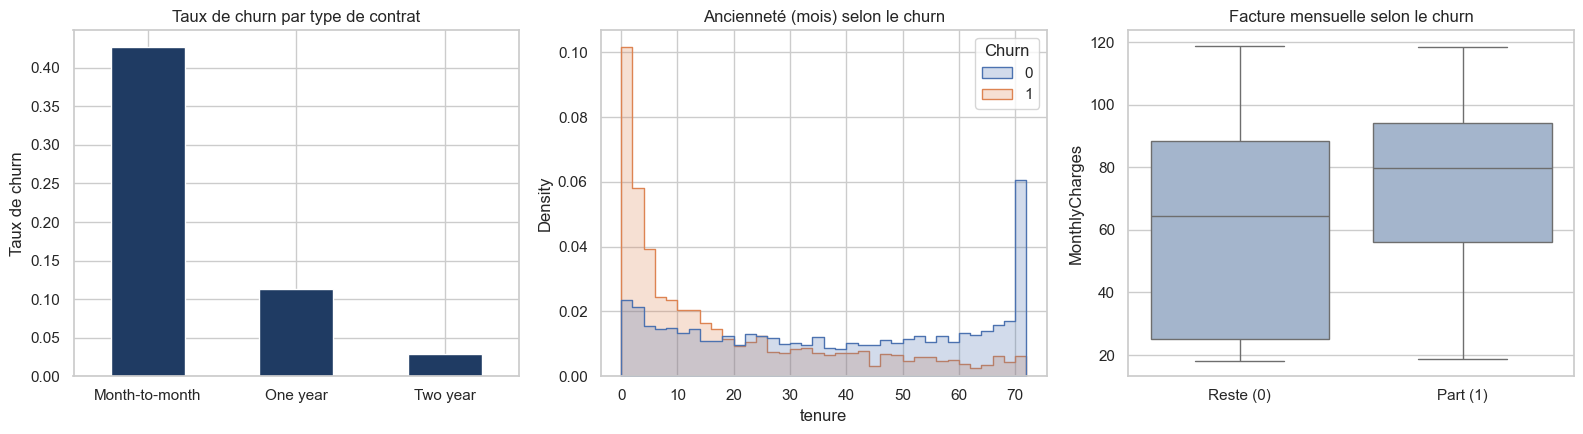

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Taux de churn par type de contrat
(df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
   .plot.bar(ax=axes[0], color="#1F3B63"))
axes[0].set_title("Taux de churn par type de contrat")
axes[0].set_ylabel("Taux de churn"); axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

# Ancienneté selon le churn
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_title("Ancienneté (mois) selon le churn")

# Facture mensuelle selon le churn
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[2], color="#9DB4D3")
axes[2].set_title("Facture mensuelle selon le churn")
axes[2].set_xticks([0, 1], ["Reste (0)", "Part (1)"]); axes[2].set_xlabel("")

plt.tight_layout()
plt.savefig("../figures/01_exploration.png", dpi=120, bbox_inches="tight")
plt.show()

**Ce que montre l'exploration :**
- Les contrats **au mois** partent beaucoup plus que les contrats d'un ou deux ans.
- Les départs sont concentrés dans les **premiers mois** d'abonnement.
- Les clients qui partent ont en moyenne une **facture mensuelle plus élevée**.

## 3. Préparation des données

In [36]:
y = df["Churn"]
X = df.drop(columns=["customerID", "Churn"])

var_num = ["tenure", "MonthlyCharges", "TotalCharges"]
var_cat = [c for c in X.columns if c not in var_num]

# Échantillon d'apprentissage (80 %) et de test (20 %).
# stratify=y garde le même taux de churn dans les deux échantillons.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Apprentissage :", X_train.shape, " | Test :", X_test.shape)
print(f"Taux de churn : {y_train.mean():.1%} (train) / {y_test.mean():.1%} (test)")

Apprentissage : (5634, 19)  | Test : (1409, 19)
Taux de churn : 26.5% (train) / 26.5% (test)


L'échantillon test est mis de côté et **ne sert qu'à la fin**. Tous les choix (modèle, seuil)
se font sur l'échantillon d'apprentissage, sinon l'évaluation finale serait trop optimiste.

La préparation est placée dans un `Pipeline` : la standardisation et l'encodage sont appris
uniquement sur les données d'apprentissage de chaque pli de validation croisée (pas de fuite de données).

In [37]:
preparation = ColumnTransformer([
    ("num", StandardScaler(), var_num),                                  # centrer-réduire
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), var_cat),  # variables indicatrices
])

## 4. Comparaison de 4 modèles par validation croisée

| Modèle | Rôle |
| --- | --- |
| Modèle naïf | Référence : prédit toujours la classe majoritaire. Tout modèle doit faire mieux. |
| Régression logistique | Modèle économétrique classique, facile à interpréter. |
| Forêt aléatoire | Beaucoup d'arbres indépendants dont on fait la moyenne. |
| XGBoost | Arbres construits les uns après les autres, chacun corrige les erreurs du précédent. |

Validation croisée à 5 plis : on découpe l'échantillon d'apprentissage en 5, on entraîne sur 4 parts
et on évalue sur la 5e, 5 fois de suite. On obtient une moyenne et un écart-type du score.

In [38]:
modeles = {
    "Modèle naïf": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=1000),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                              random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8,
                             random_state=SEED, eval_metric="logloss"),
}
pipelines = {nom: Pipeline([("prep", preparation), ("modele", m)]) for nom, m in modeles.items()}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
resultats = []
for nom, pipe in pipelines.items():
    sc = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "recall", "precision"])
    resultats.append({"Modèle": nom,
                      "AUC moyenne": sc["test_roc_auc"].mean(),
                      "AUC écart-type": sc["test_roc_auc"].std(),
                      "Rappel (seuil 0,5)": sc["test_recall"].mean(),
                      "Précision (seuil 0,5)": sc["test_precision"].mean()})
res_cv = pd.DataFrame(resultats).set_index("Modèle")
res_cv

,AUC moyenne,AUC écart-type,"Rappel (seuil 0,5)","Précision (seuil 0,5)"
Modèle,,,,
Modèle naïf,0.500,0.000,0.000,0.000
Régression logistique,0.846,0.012,0.543,0.654
Forêt aléatoire,0.845,0.011,0.502,0.672
XGBoost,0.847,0.011,0.527,0.668


**Lecture :** l'AUC mesure la capacité du modèle à classer un client qui part au-dessus d'un client
qui reste (0,5 = hasard, 1 = parfait). Le modèle naïf a une AUC de 0,5, comme attendu.
Les trois vrais modèles font nettement mieux, avec des scores proches. La régression logistique,
simple et interprétable, tient la comparaison avec les modèles d'arbres.
(Le modèle naïf ne prédit jamais de départ : sa précision n'est pas définie et vaut 0 par convention.)

## 5. Évaluation sur l'échantillon test

In [39]:
proba_test = {}
lignes = []
for nom, pipe in pipelines.items():
    if nom == "Modèle naïf":
        continue
    pipe.fit(X_train, y_train)                       # entraînement sur tout l'apprentissage
    p = pipe.predict_proba(X_test)[:, 1]             # probabilité de churn
    proba_test[nom] = p
    pred = (p >= 0.5).astype(int)
    lignes.append({"Modèle": nom,
                   "AUC": roc_auc_score(y_test, p),
                   "Rappel": recall_score(y_test, pred),
                   "Précision": precision_score(y_test, pred),
                   "F1": f1_score(y_test, pred)})
res_test = pd.DataFrame(lignes).set_index("Modèle")
res_test

,AUC,Rappel,Précision,F1
Modèle,,,,
Régression logistique,0.842,0.556,0.654,0.601
Forêt aléatoire,0.843,0.529,0.660,0.588
XGBoost,0.844,0.524,0.658,0.583


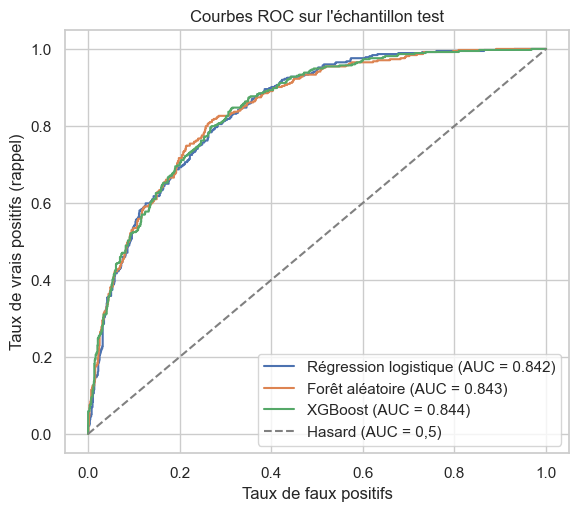

In [41]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nom, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", label="Hasard (AUC = 0,5)")
ax.set_xlabel("Taux de faux positifs"); ax.set_ylabel("Taux de vrais positifs (rappel)")
ax.set_title("Courbes ROC sur l'échantillon test")
ax.legend(loc="lower right")
plt.savefig("../figures/02_courbes_roc.png", dpi=120, bbox_inches="tight")
plt.show()

AUC de l'arbre : 0.8201193520886616


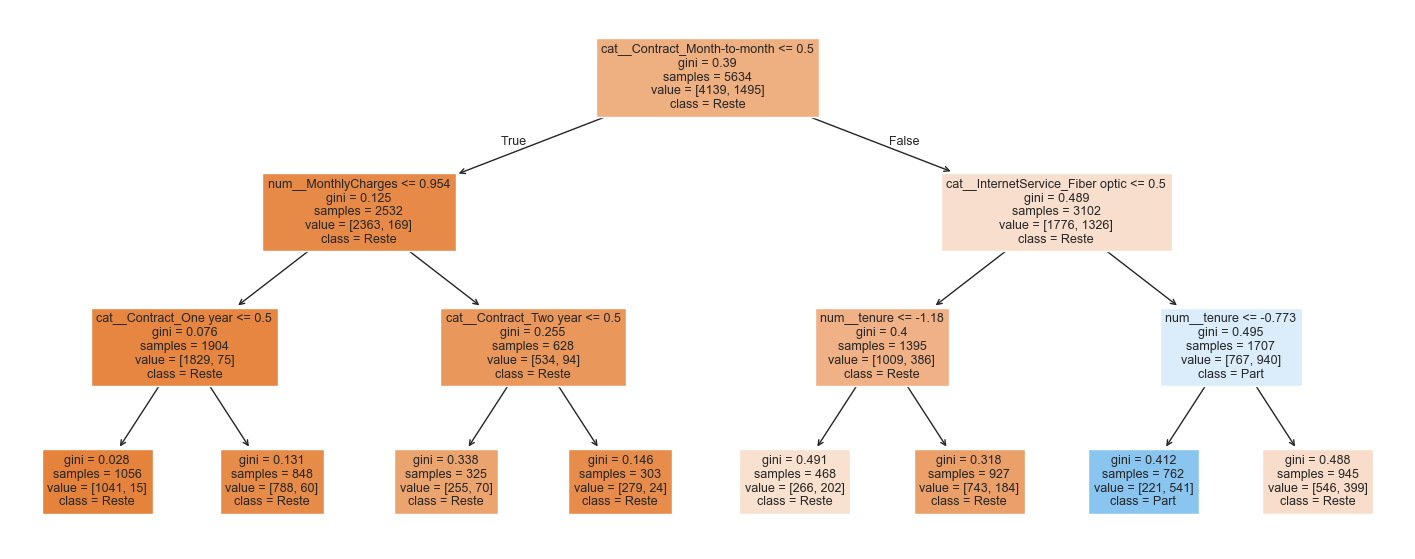

In [43]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

arbre = Pipeline([("prep", preparation),
                  ("modele", DecisionTreeClassifier(max_depth=3, random_state=42))])
arbre.fit(X_train, y_train)

y_pred = arbre.predict(X_test)                 # 0 ou 1, seuil 0,5
p = arbre.predict_proba(X_test)[:, 1]          # probabilités
print("AUC de l'arbre :", roc_auc_score(y_test, p))

# Dessiner l'arbre
plt.figure(figsize=(18, 7))
plot_tree(arbre.named_steps["modele"],
          feature_names=arbre.named_steps["prep"].get_feature_names_out(),
          class_names=["Reste", "Part"], filled=True, fontsize=9)
plt.show()

## 6. Le meilleur modèle est-il significativement meilleur ?

Les AUC sont proches. Avant de conclure qu'un modèle est meilleur, je vérifie si l'écart est
**statistiquement significatif**.

Méthode : **bootstrap**. Je tire 2 000 fois avec remise des échantillons de la taille du test,
je recalcule l'écart d'AUC à chaque fois, et je regarde l'intervalle de confiance à 95 %.
Si l'intervalle contient 0, l'écart n'est pas significatif.

In [42]:
def bootstrap_ecart_auc(y, p1, p2, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p1, p2 = np.asarray(y), np.asarray(p1), np.asarray(p2)
    ecarts = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():      # il faut les deux classes pour calculer l'AUC
            continue
        ecarts.append(roc_auc_score(y[idx], p1[idx]) - roc_auc_score(y[idx], p2[idx]))
    return np.mean(ecarts), np.percentile(ecarts, [2.5, 97.5])

ref = "Régression logistique"
for nom in ["Forêt aléatoire", "XGBoost"]:
    moy, (bas, haut) = bootstrap_ecart_auc(y_test, proba_test[nom], proba_test[ref])
    verdict = "significatif" if (bas > 0 or haut < 0) else "NON significatif"
    print(f"AUC {nom} - AUC {ref} = {moy:+.4f}  IC 95 % [{bas:+.4f} ; {haut:+.4f}]  -> {verdict}")

AUC Forêt aléatoire - AUC Régression logistique = +0.0008  IC 95 % [-0.0076 ; +0.0093]  -> NON significatif
AUC XGBoost - AUC Régression logistique = +0.0016  IC 95 % [-0.0063 ; +0.0092]  -> NON significatif


## 7. Choisir un seuil de décision selon un critère métier

Par défaut, on prédit « part » si la probabilité dépasse 0,5. Mais ce seuil n'a aucune raison
d'être le bon pour l'entreprise. Je le choisis selon le **gain d'une campagne de fidélisation**.

**Hypothèses (à adapter avec le métier) :**
- Contacter un client et lui offrir une remise coûte **50 €**.
- Parmi les clients qui allaient partir et qui sont contactés, **30 %** restent grâce à l'offre.
- Un client retenu rapporte **12 mois** de sa facture mensuelle.

Gain = valeur des clients retenus − coût total des offres.

Pour ne pas tricher, le seuil est choisi sur des prédictions **hors échantillon** de l'apprentissage
(`cross_val_predict`), puis appliqué tel quel au test.

In [44]:
COUT_OFFRE, TAUX_SUCCES, MOIS = 50, 0.30, 12

def gain_campagne(y, proba, facture, seuil):
    cible = proba >= seuil                                  # clients contactés
    retenus = cible & (y == 1)                               # vrais partants contactés
    valeur = (TAUX_SUCCES * MOIS * facture[retenus]).sum()
    return valeur - COUT_OFFRE * cible.sum()

modele_final = "Régression logistique"   # voir conclusion
pipe_final = pipelines[modele_final]

# Probabilités hors échantillon sur l'apprentissage
p_oof = cross_val_predict(pipe_final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
seuils = np.round(np.arange(0.05, 0.95, 0.01), 2)
gains_train = [gain_campagne(y_train.values, p_oof, X_train["MonthlyCharges"].values, s) for s in seuils]
seuil_opt = seuils[int(np.argmax(gains_train))]
print(f"Seuil choisi sur l'apprentissage : {seuil_opt:.2f}")

# Application au test
fact_test = X_test["MonthlyCharges"].values
p_final = proba_test[modele_final]
comparaison = pd.DataFrame({
    "Stratégie": ["Ne contacter personne", "Seuil standard 0,5", f"Seuil optimisé {seuil_opt:.2f}", "Contacter tout le monde"],
    "Clients contactés": [0, (p_final >= 0.5).sum(), (p_final >= seuil_opt).sum(), len(p_final)],
    "Gain (€)": [0, gain_campagne(y_test.values, p_final, fact_test, 0.5),
                 gain_campagne(y_test.values, p_final, fact_test, seuil_opt),
                 gain_campagne(y_test.values, p_final, fact_test, 0.0)],
}).set_index("Stratégie")
comparaison["Gain (€)"] = comparaison["Gain (€)"].round(0)
comparaison

Seuil choisi sur l'apprentissage : 0.26


,Clients contactés,Gain (€)
Stratégie,,
Ne contacter personne,0,0.0
"Seuil standard 0,5",318,43213.0
Seuil optimisé 0.26,588,52079.0
Contacter tout le monde,1409,27524.0


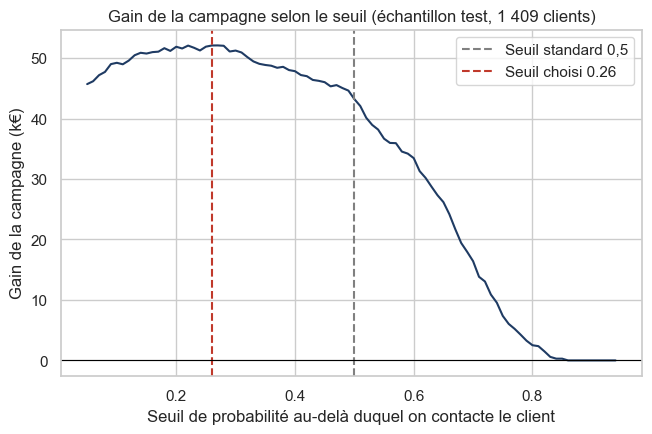

Matrice de confusion au seuil choisi (lignes = réel, colonnes = prédit) :
       Prédit reste  Prédit part
Reste           745          290
Part             76          298


In [45]:
gains_test = [gain_campagne(y_test.values, p_final, fact_test, s) for s in seuils]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(seuils, np.array(gains_test) / 1000, color="#1F3B63")
ax.axvline(0.5, ls="--", color="grey", label="Seuil standard 0,5")
ax.axvline(seuil_opt, ls="--", color="#C0392B", label=f"Seuil choisi {seuil_opt:.2f}")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Seuil de probabilité au-delà duquel on contacte le client")
ax.set_ylabel("Gain de la campagne (k€)")
ax.set_title("Gain de la campagne selon le seuil (échantillon test, 1 409 clients)")
ax.legend()
plt.savefig("../figures/03_gain_seuil.png", dpi=120, bbox_inches="tight")
plt.show()

cm = confusion_matrix(y_test, (p_final >= seuil_opt).astype(int))
print("Matrice de confusion au seuil choisi (lignes = réel, colonnes = prédit) :")
print(pd.DataFrame(cm, index=["Reste", "Part"], columns=["Prédit reste", "Prédit part"]))

## 8. Interprétation

### Régression logistique : odds ratios

Je réestime la régression logistique avec `statsmodels` pour obtenir les odds ratios et les p-valeurs,
comme en économétrie. Deux variables sont retirées pour éviter une forte **colinéarité**,
qui rendrait les coefficients instables et absurdes :
- `TotalCharges` ≈ ancienneté × facture mensuelle ;
- `MonthlyCharges` ≈ somme des prix des options souscrites (fibre, TV, films…).
  Avec elle dans le modèle, l'effet de chaque option serait mélangé avec celui du prix.

Pour la prédiction, ces variables ne posent pas de problème ; pour l'interprétation, si.

In [ ]:
X_eco = pd.get_dummies(X_train.drop(columns=["TotalCharges", "MonthlyCharges"]),
                       drop_first=True, dtype=float)
# Ancienneté centrée-réduite : l'odds ratio se lit "pour un écart-type de plus (environ 2 ans)"
X_eco["tenure"] = (X_eco["tenure"] - X_eco["tenure"].mean()) / X_eco["tenure"].std()
logit = sm.Logit(y_train.values, sm.add_constant(X_eco)).fit(disp=0)

table = pd.DataFrame({"Odds ratio": np.exp(logit.params),
                      "IC 2,5 %": np.exp(logit.conf_int()[0]),
                      "IC 97,5 %": np.exp(logit.conf_int()[1]),
                      "p-valeur": logit.pvalues}).drop("const")
table[table["p-valeur"] < 0.05].sort_values("Odds ratio")

,Odds ratio,"IC 2,5 %","IC 97,5 %",p-valeur
Contract_Two year,0.256,0.175,0.375,2.087e-12
InternetService_No,0.434,0.320,0.589,8.153e-08
tenure,0.448,0.395,0.509,3.512e-35
Contract_One year,0.496,0.392,0.628,5.624e-09
PhoneService_Yes,0.627,0.475,0.828,1.015e-03
OnlineSecurity_Yes,0.675,0.561,0.813,3.307e-05
TechSupport_Yes,0.712,0.590,0.859,3.800e-04
Dependents_Yes,0.790,0.648,0.962,1.880e-02
StreamingMovies_Yes,1.325,1.112,1.579,1.623e-03
StreamingTV_Yes,1.326,1.113,1.579,1.581e-03


**Lecture d'un odds ratio :** un odds ratio de 0,5 signifie que la cote de départ est divisée par 2
par rapport à la modalité de référence, toutes choses égales par ailleurs. Au-dessus de 1, le risque augmente.
Seules les variables significatives au seuil de 5 % sont affichées.

### XGBoost : valeurs SHAP

Les modèles d'arbres ne donnent pas de coefficients. Les **valeurs SHAP** mesurent la contribution
de chaque variable à la prédiction de chaque client. Le graphique montre les variables les plus
influentes et le sens de leur effet.

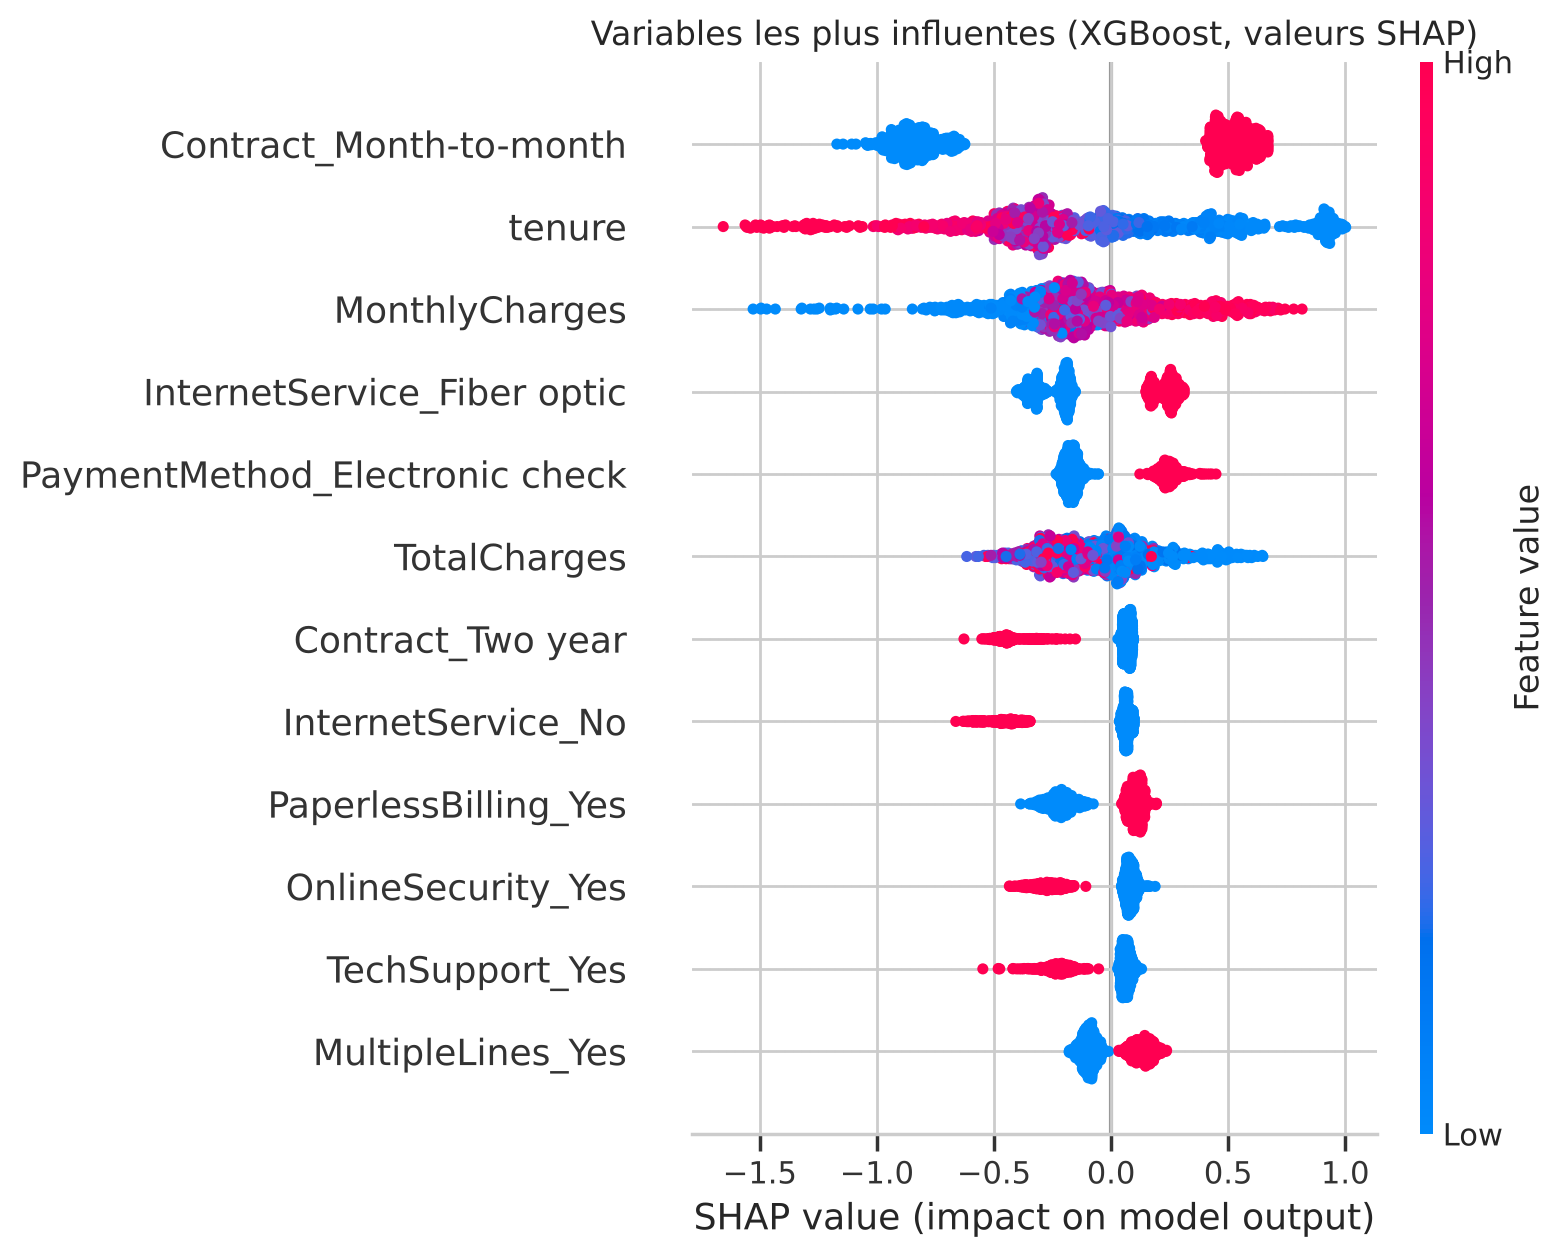

In [ ]:
pipe_xgb = pipelines["XGBoost"]
X_test_prep = pipe_xgb.named_steps["prep"].transform(X_test)
noms = pipe_xgb.named_steps["prep"].get_feature_names_out()
noms = [n.split("__", 1)[1] for n in noms]          # enlève les préfixes "num__" et "cat__"

explainer = shap.TreeExplainer(pipe_xgb.named_steps["modele"])
valeurs_shap = explainer.shap_values(X_test_prep)

shap.summary_plot(valeurs_shap, pd.DataFrame(X_test_prep, columns=noms),
                  max_display=12, show=False)
plt.title("Variables les plus influentes (XGBoost, valeurs SHAP)")
plt.savefig("../figures/04_shap.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Conclusion

- **Modèle retenu : la régression logistique.** Les modèles d'arbres ne font pas significativement mieux
  (test bootstrap), et la régression logistique est plus simple à expliquer aux équipes métier.
- **Facteurs de départ** (confirmés par les deux méthodes d'interprétation) : contrat au mois,
  faible ancienneté, fibre optique, paiement par chèque électronique, absence de services d'assistance.
- **Valeur métier :** choisir le seuil selon le gain de la campagne plutôt que 0,5 augmente
  le gain estimé (voir tableau de la partie 7).

**Pistes d'action :** proposer aux clients au mois un passage à un contrat d'un an,
soigner l'accueil des nouveaux clients pendant les premiers mois, enquêter sur la satisfaction
des clients fibre.

**Limites :**
- Données fictives d'IBM, sans dimension temporelle (une seule photo des clients).
- Hypothèses de coût et de taux de succès de l'offre à valider avec le métier.
- Hyperparamètres des modèles d'arbres peu optimisés : une recherche par grille pourrait les améliorer légèrement.